# 05 · Avaliação

**CRISP-DM fase 5 — avaliação** · Telco Customer Churn

---

Esta fase avalia o projeto como um todo e o modelo selecionado sob a ótica do negócio: **segmentar a carteira para orientar ações de retenção**.

| Etapa | Entrega |
|---|---|
| **5.1 Avaliar os resultados** | modelo validado contra os critérios de sucesso · impacto financeiro e operacional estimado · decisão formal sobre a implantação |
| **5.2 Revisar o processo** | análise das fases concluídas · lacunas e erros documentados · sumário das descobertas e limitações |
| **5.3 Determinar as próximas etapas** | próxima ação (Implantação, Iterar mais ou Novo projeto) · justificativa formalizada |

Entradas:
* os segmentos e o resumo do modelo vencedor, salvos pelo [`04-0-modelagem-cluster`](04-0-modelagem-cluster.ipynb);
* a base pré-processada do [`03-preparacao`](03-preparacao.ipynb), o mesmo espaço em que o modelo foi treinado;
* a base curada do [`02-ajustes-dados`](02-ajustes-dados.ipynb), que dá as unidades de negócio;
* a base bruta, **só** para o `customerID` (quem está em cada segmento).

**`Churn` não é usado neste notebook.** Ele foi retirado no notebook 01 e o projeto é não supervisionado do início ao fim: os segmentos são avaliados por métricas internas e pelo perfil em unidades de negócio.

In [1]:
import json
import warnings
warnings.filterwarnings('ignore')  # silencia avisos de convergência

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier            # classifica clientes novos nos segmentos
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

## Critérios e premissas

**Confira estes valores com os critérios de sucesso do projeto** (`docs/criterios-sucesso.md`). Eles definem se o modelo é aprovado.

* **Críticos:** traduzem o uso do modelo pela área de retenção. Se algum falhar, o modelo não vai para implantação.
* **Não críticos:** qualidade técnica. Se falharem, o modelo pode seguir, mas com ressalva.

As premissas financeiras são **hipotéticas** e precisam ser validadas com a área de negócio antes de qualquer decisão.

In [2]:
# Critérios de sucesso do negócio
K_MIN, K_MAX = 2, 5           # crítico · número de segmentos que a área de retenção consegue operar (um playbook por segmento)
FATIA_MINIMA = 0.10           # crítico · menor segmento com ao menos 10% da carteira (abaixo disso não paga uma ação dedicada)
ACURACIA_MINIMA = 0.85        # crítico · cliente novo cai no segmento certo em ao menos 85% dos casos
ESTABILIDADE_MINIMA = 0.80    # crítico · ARI médio entre a partição original e a refeita em reamostragens
SILHUETA_MINIMA = 0.25        # não crítico · separação geométrica dos grupos
REDUNDANCIA_MAXIMA = 0.90     # não crítico · ARI máximo entre os segmentos e uma única variável (acima disso, a variável sozinha basta)
REAMOSTRAGENS = 10            # bootstrap da estabilidade

# Premissas financeiras (hipotéticas: validar com a área de negócio)
RECEITA_PROTEGIDA = {'pessimista': 0.02, 'base': 0.05, 'otimista': 0.08}  # fração da receita anual do segmento prioritário que a ação deixa de perder
CUSTO_CONTATO = 15            # US$ por cliente abordado (ligação, oferta, desconto médio)
CUSTO_IMPLANTACAO = 50_000    # US$, uma vez: integração com o CRM, treinamento da equipe
CUSTO_ANUAL = 20_000          # US$ por ano: manutenção e re-treino do modelo

In [ ]:
X = pd.read_csv('../data/processed/Telcon-Customer-Churn_preprocessed.csv', sep=',')  # saída do 03: o espaço do modelo
colunas = X.columns
X = X.to_numpy(dtype=float)

df = pd.read_csv('../data/processed/Telcon-Customer-Churn_tratado.csv', sep=',')           # base curada (02), em unidades de negócio
bruta = pd.read_csv('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv', sep=',',
                    usecols=['customerID', 'tenure', 'MonthlyCharges'])                    # só o customerID (tenure e mensalidade conferem a ordem)
segmentos = pd.read_csv('../data/processed/segmentos.csv', sep=',')['segmento'].to_numpy()  # rótulos do vencedor (04-0)
selecionado = json.loads(Path('../models/selecionado.json').read_text(encoding='utf-8'))    # nome, parâmetros e silhueta do vencedor

# As bases precisam estar alinhadas linha a linha: o 02 mantém a ordem da base bruta
assert len(X) == len(df) == len(bruta) == len(segmentos), 'bases com tamanhos diferentes'
assert np.array_equal(df['tenure'], bruta['tenure']) and np.allclose(df['MonthlyCharges'], bruta['MonthlyCharges']), \
    'a base curada não está na ordem da base bruta'

df['customerID'] = bruta['customerID'].to_numpy()                  # quem é cada cliente (não entra em nenhum cálculo)
validos = segmentos >= 0                                           # −1 é ruído (só no dbscan): cliente sem segmento

display(Markdown(
    f"Modelo selecionado: **{selecionado['modelo']}** · `{selecionado['params']}` · "
    f"**{selecionado['grupos']}** segmentos · silhueta **{selecionado['silhueta']:.3f}** · "
    f"clientes sem segmento: **{(~validos).sum()}**"
))

Modelo selecionado: **dbscan** · `{'eps': 1.42}` · **3** segmentos · silhueta **0.187** · clientes sem segmento: **24**

# 5.1 · Avaliar os resultados (negócio)

## Os segmentos em unidades de negócio

Os segmentos são renomeados de A em diante, **do menor para o maior tempo de casa** (`tenure` mediano). A numeração do algoritmo é arbitrária e não deve chegar à equipe de retenção. A ordem usa só uma variável do próprio modelo.

In [4]:
ordem = (pd.Series(df.loc[validos, 'tenure'].to_numpy(), index=segmentos[validos])
         .groupby(level=0).median().sort_values(kind='stable').index)            # do mais novo ao mais antigo na casa
nome = {int(s): f'Segmento {chr(65 + i)}' for i, s in enumerate(ordem)}          # 0, 1, 2… → Segmento A, B, C…
df['segmento'] = pd.Series(segmentos).map(nome).fillna('Sem segmento').to_numpy()  # ruído vira "Sem segmento"

protecao = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
df['ServicosProtecao'] = df[protecao].eq('Yes').sum(axis=1)                      # mesma regra do 03 (0 a 4)

perfil = (
    df.assign(mensal=df['Contract'].eq('Month-to-month'),
              fibra=df['InternetService'].eq('Fiber optic'),
              cheque_eletronico=df['PaymentMethod'].eq('Electronic check'),
              idoso=df['SeniorCitizen'].eq('Yes'))
    .groupby('segmento')
    .agg(clientes=('tenure', 'size'),
         tenure=('tenure', 'median'),                         # meses de casa
         mensalidade=('MonthlyCharges', 'median'),            # US$ por mês
         gasto_total=('TotalCharges', 'median'),              # US$ acumulado
         receita_mensal=('MonthlyCharges', 'sum'),            # US$ por mês que o segmento traz
         protecao=('ServicosProtecao', 'mean'),               # nº médio de serviços de proteção (0 a 4)
         contrato_mensal=('mensal', 'mean'),
         fibra=('fibra', 'mean'),
         cheque_eletronico=('cheque_eletronico', 'mean'),
         idoso=('idoso', 'mean'))
    .assign(participacao=lambda d: d['clientes'] / len(df))  # fatia da carteira
)
perfil = perfil.loc[[n for n in sorted(perfil.index) if n != 'Sem segmento'] + (['Sem segmento'] if 'Sem segmento' in perfil.index else [])]

perfil.style.format({'tenure': '{:.0f}', 'mensalidade': '${:,.2f}', 'gasto_total': '${:,.0f}', 'receita_mensal': '${:,.0f}',
                     'protecao': '{:.1f}', 'contrato_mensal': '{:.0%}', 'fibra': '{:.0%}', 'cheque_eletronico': '{:.0%}',
                     'idoso': '{:.0%}', 'participacao': '{:.1%}'})

,clientes,tenure,mensalidade,gasto_total,receita_mensal,protecao,contrato_mensal,fibra,cheque_eletronico,idoso,participacao
segmento,,,,,,,,,,,
Segmento A,1525,25,$20.15,$520,"$32,146",0.0,34%,0%,8%,3%,21.7%
Segmento B,2410,29,$56.15,"$1,591","$140,025",1.9,51%,0%,27%,10%,34.2%
Segmento C,3084,30,$91.65,"$2,654","$282,174",1.4,69%,100%,52%,27%,43.8%
Sem segmento,24,46,$81.53,"$3,407","$1,772",2.2,4%,50%,46%,46%,0.3%


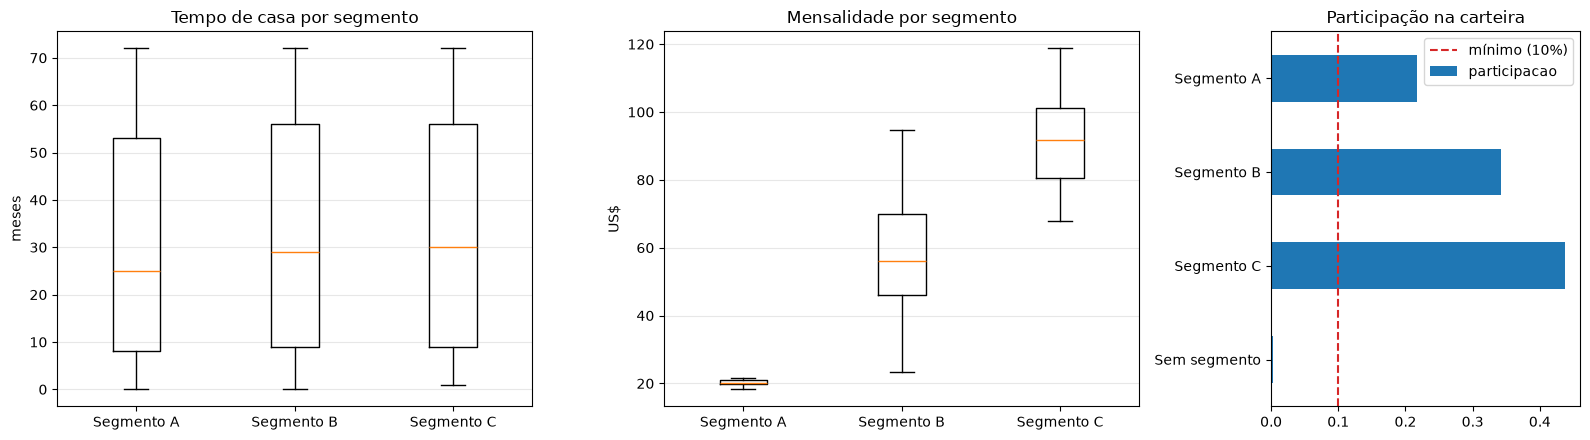

In [5]:
ordem_nomes = [n for n in perfil.index if n != 'Sem segmento']

fig, (ax_ten, ax_men, ax_fatia) = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={'width_ratios': [2, 2, 1.3]})
for ax, coluna, titulo, unidade in ((ax_ten, 'tenure', 'Tempo de casa por segmento', 'meses'),
                                    (ax_men, 'MonthlyCharges', 'Mensalidade por segmento', 'US$')):
    ax.boxplot([df.loc[df['segmento'] == n, coluna] for n in ordem_nomes], showfliers=False)
    ax.set_xticks(range(1, len(ordem_nomes) + 1), ordem_nomes)
    ax.set(title=titulo, ylabel=unidade)
    ax.grid(alpha=0.3, axis='y')

perfil['participacao'].plot.barh(ax=ax_fatia, color='tab:blue')                 # tamanho de cada segmento
ax_fatia.axvline(FATIA_MINIMA, color='tab:red', ls='--', label=f'mínimo ({FATIA_MINIMA:.0%})')
ax_fatia.set(title='Participação na carteira', ylabel='')
ax_fatia.invert_yaxis()
ax_fatia.legend()
fig.tight_layout()
plt.show()

## Validação contra os critérios de sucesso

* **Tamanho e número de segmentos:** cada segmento precisa ser grande o bastante para pagar uma ação dedicada, e o total precisa caber na operação.
* **Cliente novo classificável:** uma random forest aprende a atribuir o segmento a partir das mesmas features. A acurácia em validação cruzada estima quantos clientes novos seriam classificados corretamente. É o que viabiliza o uso diário, inclusive quando o algoritmo vencedor não classifica clientes novos sozinho (DBSCAN e Ward não têm `predict`).
* **Estabilidade:** o algoritmo vencedor é treinado de novo em reamostragens da carteira (bootstrap). O ARI (*adjusted Rand index*, 0 = acaso, 1 = idêntico) mede se os mesmos clientes continuam juntos. Segmento que muda a cada reamostragem não sustenta um playbook.
* **Separação geométrica:** silhueta e Davies-Bouldin (quanto menor, melhor), recalculados na base atual.
* **Segmentos além de uma variável:** se uma única coluna da base curada (ex.: `InternetService`) reproduz os segmentos, o modelo não acrescenta nada a um filtro simples. O ARI entre os segmentos e cada variável mede isso (numéricas cortadas em quintis).

In [6]:
rotulos = segmentos[validos]
k = len(np.unique(rotulos))                                                       # segmentos formados (sem ruído)
fatia_min = pd.Series(rotulos).value_counts().min() / len(df)                     # tamanho do menor segmento
silhueta = silhouette_score(X[validos], rotulos)                                  # recalculada na base atual
davies_bouldin = davies_bouldin_score(X[validos], rotulos)                        # informativo: menor = grupos mais compactos e separados

classificador = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
acuracia = cross_val_score(classificador, X[validos], rotulos,
                           cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean()  # acerto em clientes fora do treino

# Estabilidade: refaz o vencedor em reamostragens e compara com a partição original nos mesmos clientes
try:
    modelo = joblib.load(Path('../models') / selecionado['arquivo'])              # k-medianas/k-medoides só carregam onde a classe existe
    rng = np.random.default_rng(42)
    aris = []
    for _ in range(REAMOSTRAGENS):
        amostra = rng.choice(len(X), len(X), replace=True)
        novos = clone(modelo).fit_predict(X[amostra])
        aris.append(adjusted_rand_score(segmentos[amostra], novos))
    estabilidade = float(np.mean(aris))
except Exception as erro:
    estabilidade = np.nan
    print(f'Estabilidade não calculada ({type(erro).__name__}: {erro})')

# Redundância: algum filtro de uma variável só reproduz os segmentos?
originais = df.drop(columns=['customerID', 'segmento'])
redundancia = pd.Series({
    c: adjusted_rand_score(rotulos, (pd.qcut(originais[c], 5, duplicates='drop', labels=False)
                                     if pd.api.types.is_numeric_dtype(originais[c]) and originais[c].nunique() > 5
                                     else originais[c])[validos])
    for c in originais.columns}).sort_values(ascending=False)
var_redundante = redundancia.index[0]

linhas = [  # (critério, meta, obtido, atende, crítico)
    ('Segmentos operáveis', f'{K_MIN} a {K_MAX}', f'{k}', K_MIN <= k <= K_MAX, True),
    ('Menor segmento', f'≥ {FATIA_MINIMA:.0%} da carteira', f'{fatia_min:.1%}', fatia_min >= FATIA_MINIMA, True),
    ('Cliente novo classificável', f'acurácia ≥ {ACURACIA_MINIMA:.0%}', f'{acuracia:.1%}', acuracia >= ACURACIA_MINIMA, True),
    ('Segmentos estáveis', f'ARI ≥ {ESTABILIDADE_MINIMA}', f'{estabilidade:.3f}', bool(estabilidade >= ESTABILIDADE_MINIMA), True),
]
linhas += [
    ('Separação dos grupos', f'silhueta ≥ {SILHUETA_MINIMA}', f'{silhueta:.3f} (Davies-Bouldin {davies_bouldin:.2f})',
     silhueta >= SILHUETA_MINIMA, False),
    ('Segmentos além de uma variável', f'ARI com qualquer variável < {REDUNDANCIA_MAXIMA}',
     f'{redundancia.iloc[0]:.3f} ({var_redundante})', redundancia.iloc[0] < REDUNDANCIA_MAXIMA, False),
    ('Cobertura da carteira', '100% com segmento', f'{validos.mean():.1%}', bool(validos.all()), False),
]
avaliacao = pd.DataFrame(linhas, columns=['critério', 'meta', 'obtido', 'atende', 'crítico'])

(avaliacao.assign(atende=avaliacao['atende'].map({True: '✓', False: '✗'}),
                  crítico=avaliacao['crítico'].map({True: 'sim', False: 'não'}))
 .style.hide(axis='index')
 .apply(lambda linha: ['background-color: #fde2e1' if linha['atende'] == '✗' else ''] * len(linha), axis=1))  # falhas em vermelho

critério,meta,obtido,atende,crítico
Segmentos operáveis,2 a 5,3,✓,sim
Menor segmento,≥ 10% da carteira,21.7%,✓,sim
Cliente novo classificável,acurácia ≥ 85%,100.0%,✓,sim
Segmentos estáveis,ARI ≥ 0.8,0.994,✓,sim
Separação dos grupos,silhueta ≥ 0.25,0.187 (Davies-Bouldin 2.05),✗,não
Segmentos além de uma variável,ARI com qualquer variável < 0.9,1.000 (InternetService),✗,não
Cobertura da carteira,100% com segmento,99.7%,✗,não


## Impacto financeiro e operacional

**Segmento prioritário.** A prioridade sai de um critério de negócio declarado antes de olhar o resultado: o segmento com **maior fatia em contrato mês a mês**, porque esse cliente pode sair a qualquer momento sem multa. Em caso de empate, decide a receita mensal do segmento.

**Financeiro.** A ação de retenção aborda todos os clientes do segmento prioritário. Cada cenário supõe que a ação protege uma fração da receita anual desse segmento (`RECEITA_PROTEGIDA`). O custo é o contato com cada cliente abordado, mais a implantação e a manutenção do modelo no ano 1. As frações são **hipóteses a validar com o negócio**, não medidas da base.

In [7]:
segmentados = perfil.drop(index='Sem segmento', errors='ignore')
alvo = segmentados.sort_values(['contrato_mensal', 'receita_mensal'], ascending=False).index[0]   # segmento prioritário
abordados = int(perfil.loc[alvo, 'clientes'])
receita_anual_alvo = perfil.loc[alvo, 'receita_mensal'] * 12                                      # US$ por ano que o segmento traz

cenarios = (
    pd.DataFrame({'receita_protegida': RECEITA_PROTEGIDA})
    .assign(
        ganho=lambda d: receita_anual_alvo * d['receita_protegida'],                                 # receita que deixa de sair
        custo_campanha=abordados * CUSTO_CONTATO,
        resultado_ano1=lambda d: d['ganho'] - d['custo_campanha'] - CUSTO_IMPLANTACAO - CUSTO_ANUAL,
        roi_ano1=lambda d: d['resultado_ano1'] / (d['custo_campanha'] + CUSTO_IMPLANTACAO + CUSTO_ANUAL),
    )
)
display(Markdown(f'Segmento prioritário: **{alvo}** · {abordados:,} clientes · '
                 f'{perfil.loc[alvo, "contrato_mensal"]:.0%} em contrato mês a mês · '
                 f'receita anual **${receita_anual_alvo:,.0f}**'.replace(',', '.')))
display(cenarios.style.format({'receita_protegida': '{:.0%}', 'ganho': '${:,.0f}', 'custo_campanha': '${:,.0f}',
                               'resultado_ano1': '${:,.0f}', 'roi_ano1': '{:.0%}'}))
cenario_base_positivo = cenarios.loc['base', 'resultado_ano1'] > 0

Segmento prioritário: **Segmento C** · 3.084 clientes · 69% em contrato mês a mês · receita anual **$3.386.087**

,receita_protegida,ganho,custo_campanha,resultado_ano1,roi_ano1
pessimista,2%,"$67,722","$46,260","$-48,538",-42%
base,5%,"$169,304","$46,260","$53,044",46%
otimista,8%,"$270,887","$46,260","$154,627",133%


In [8]:
# Operacional: o que muda na rotina da equipe de retenção
operacional = pd.DataFrame({
    'indicador': ['Playbooks de retenção a manter', 'Clientes da carteira com segmento', 'Clientes novos classificados corretamente',
                  'Maior segmento (concentração da carga)', 'Segmento prioritário', 'Re-treino recomendado'],
    'valor': [f'{k} (um por segmento)', f'{validos.mean():.1%}', f'{acuracia:.1%}',
              f'{perfil["participacao"].max():.1%} da carteira', f'{alvo} (maior fatia em contrato mês a mês)',
              'semestral ou quando o perfil da base mudar (monitoramento do 06)'],
})
operacional.style.hide(axis='index')

indicador,valor
Playbooks de retenção a manter,3 (um por segmento)
Clientes da carteira com segmento,99.7%
Clientes novos classificados corretamente,100.0%
Maior segmento (concentração da carga),43.8% da carteira
Segmento prioritário,Segmento C (maior fatia em contrato mês a mês)
Re-treino recomendado,semestral ou quando o perfil da base mudar (monitoramento do 06)


## Decisão formal sobre a implantação

In [9]:
falhas_criticas = avaliacao.query('crítico and not atende')['critério'].tolist()
ressalvas = avaliacao.query('not crítico and not atende')['critério'].tolist()

aprovado = not falhas_criticas and cenario_base_positivo           # aprova se nenhum critério crítico falha e o cenário base se paga
resultado_base = f"${cenarios.loc['base', 'resultado_ano1']:,.0f}"
display(Markdown(
    f"### {'✓ Aprovado' if aprovado else '✗ Não aprovado'} para implantação\n"
    f"- critérios críticos que falharam: **{', '.join(falhas_criticas) or 'nenhum'}**\n"
    f"- ressalvas (não críticos): **{', '.join(ressalvas) or 'nenhuma'}**\n"
    f"- resultado do ano 1 no cenário base: **{resultado_base}**"
))

### ✓ Aprovado para implantação
- critérios críticos que falharam: **nenhum**
- ressalvas (não críticos): **Separação dos grupos, Segmentos além de uma variável, Cobertura da carteira**
- resultado do ano 1 no cenário base: **$53,044**

| Registro da decisão | |
|---|---|
| Responsável pela aprovação | *preencher* |
| Data | *preencher* |
| Decisão | *copiar da célula acima* |
| Condições ou ressalvas aceitas | *preencher* |

# 5.2 · Revisar o processo

## Análise das fases

| Fase | Notebook | O que entregou | Status |
|---|---|---|---|
| 1 · Entendimento do negócio | docs | objetivo de retenção · critérios de sucesso | ⚠ `docs/criterios-sucesso.md` ainda é o modelo: conferir os critérios acima |
| 2 · Entendimento dos dados | 00 · 01 | dicionário · EDA · `Churn` retirado (projeto não supervisionado) | ✓ |
| 3 · Preparação | 02 · 03 | base curada (7.043 × 19) · `ServicosProtecao` · MinMax + one-hot (20 features) · pré-processador salvo | ✓ |
| 4 · Modelagem | 04-0 · 04-1 · 04-2 · 04-3 | 11 algoritmos comparados · cotovelos · PCA/UMAP · regras de associação | ⚠ ver lacunas 1 a 5 |
| 5 · Avaliação | 05 | este notebook | — |

## Lacunas e erros identificados

| # | Lacuna | Onde | Efeito | Correção |
|---|---|---|---|---|
| 1 | separador dos CSVs: o 03 grava com `;` e os 04 liam com `,` | 04-0 · 04-1 · 04-2 · 04-3 | os notebooks 04 não rodavam sobre a saída atual do 03 | padronizar `sep=';'` em leituras e gravações |
| 2 | 04-0 escolhe o DBSCAN, mas o 04-1 conclui que o empate técnico com o K-Means (0,187 × 0,186) se desfaz a favor do K-Means | 04-0 · 04-1 | o DBSCAN não classifica clientes novos e deixa clientes sem segmento | desempate de negócio declarado na regra do 04-0 |
| 3 | texto e comentários herdados do projeto imobiliário (imóveis, preço de venda, Meridiano) | 04-0 · 04-1 · 04-2 · 04-3 | confunde a leitura e a apresentação | revisar os textos |
| 4 | a seção "O que leva ao preço" do 04-3 procura `preco_venda`, que não existe nesta base | 04-3 | tabelas vazias | trocar por consequentes de negócio (ex.: `Contract=Month-to-month`) |
| 5 | silhueta baixa em todos os algoritmos (≤ 0,19) | 04-0 · 04-1 | os perfis formam um contínuo, sem ilhas bem separadas | testar o agrupamento sobre as bases reduzidas do 04-2, medindo a silhueta no espaço original |
| 6 | sem rótulo de cancelamento, a prioridade e o impacto se apoiam em um indicador (contrato mês a mês) e em premissas | 05 | o segmento prioritário é uma hipótese de negócio | medir o resultado da ação com grupo de controle na implantação (06) |
| 7 | K-Medianas e K-Medoids são classes definidas no notebook | 04-0 | o `.joblib` só carrega onde a classe existe | mover as classes para `src` se um deles vencer |
| 8 | premissas financeiras sem validação | 05 | o impacto pode estar super ou subestimado | validar receita protegida, custo de contato e custos fixos com o negócio |

## Sumário das descobertas

O que diferencia os segmentos: a importância de cada variável no classificador, somada por variável de origem (o one-hot é desfeito).

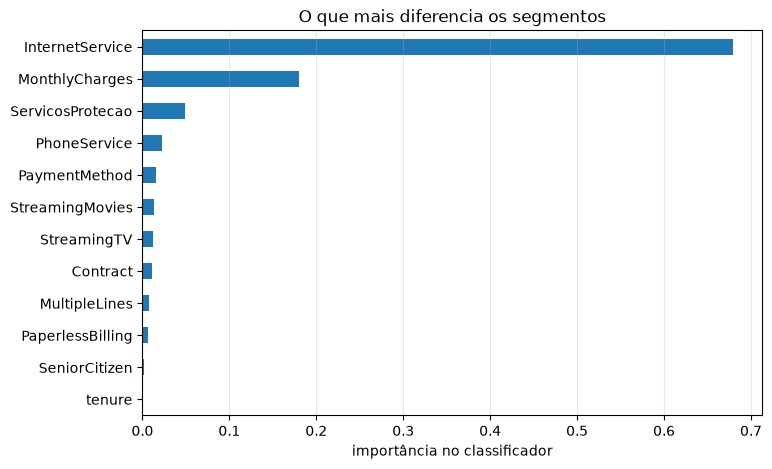

In [10]:
classificador.fit(X[validos], rotulos)                                            # treina na carteira inteira para ler as importâncias
variavel = {c: max((o for o in df.columns if c == o or c.startswith(f'{o}_')), key=len, default=c)
            for c in colunas}                                                     # feature → variável de origem
importancia = (pd.Series(classificador.feature_importances_, index=colunas)
               .groupby(variavel).sum().sort_values(ascending=False))              # relevância por variável

ax = importancia.head(12)[::-1].plot.barh(figsize=(8, 5), color='tab:blue')
ax.set(title='O que mais diferencia os segmentos', xlabel='importância no classificador')
ax.grid(alpha=0.3, axis='x')
plt.show()

In [11]:
descobertas = [
    f"A carteira foi dividida em **{k} segmentos** pelo {selecionado['modelo']}; o menor tem {fatia_min:.1%} dos clientes.",
    f"O tempo de casa mediano vai de **{perfil.loc[ordem_nomes, 'tenure'].min():.0f}** a **{perfil.loc[ordem_nomes, 'tenure'].max():.0f} meses** "
    f"e a mensalidade mediana de **${perfil.loc[ordem_nomes, 'mensalidade'].min():,.2f}** a **${perfil.loc[ordem_nomes, 'mensalidade'].max():,.2f}**.",
    f"As variáveis que mais separam os segmentos são **{', '.join(importancia.index[:3])}**.",
    f"Um cliente novo é atribuído ao segmento certo em **{acuracia:.1%}** dos casos; a partição tem estabilidade (ARI) de **{estabilidade:.2f}**.",
    f"A variável que mais se parece com os segmentos é **{var_redundante}** (ARI {redundancia.iloc[0]:.2f})"
    + (": **os segmentos praticamente repetem essa coluna**." if redundancia.iloc[0] >= REDUNDANCIA_MAXIMA else '.'),
    f"A separação geométrica é {'adequada' if silhueta >= SILHUETA_MINIMA else '**fraca**'} (silhueta {silhueta:.3f}): "
    "os segmentos são faixas de uma carteira contínua, não grupos isolados.",
]
descobertas.append(
    f"O segmento prioritário é **{alvo}**: {perfil.loc[alvo, 'contrato_mensal']:.0%} em contrato mês a mês, "
    f"{perfil.loc[alvo, 'participacao']:.1%} da carteira e receita de ${perfil.loc[alvo, 'receita_mensal']:,.0f} por mês.")

limitacoes = [
    "A base é um retrato de um único momento (dataset público da IBM): a representatividade para a carteira atual precisa ser confirmada.",
    "O projeto é não supervisionado: não há rótulo para confirmar que o segmento prioritário é o de maior risco de cancelamento.",
    "O impacto financeiro depende de premissas não validadas (seção 5.1).",
    "Os segmentos refletem as escolhas de pré-processamento do 03 (MinMax + one-hot); com outro peso para as categorias, eles podem mudar.",
]
display(Markdown('**Descobertas**\n' + '\n'.join(f'- {d}' for d in descobertas)
                 + '\n\n**Limitações do modelo**\n' + '\n'.join(f'- {l}' for l in limitacoes)))

**Descobertas**
- A carteira foi dividida em **3 segmentos** pelo dbscan; o menor tem 21.7% dos clientes.
- O tempo de casa mediano vai de **25** a **30 meses** e a mensalidade mediana de **$20.15** a **$91.65**.
- As variáveis que mais separam os segmentos são **InternetService, MonthlyCharges, ServicosProtecao**.
- Um cliente novo é atribuído ao segmento certo em **100.0%** dos casos; a partição tem estabilidade (ARI) de **0.99**.
- A variável que mais se parece com os segmentos é **InternetService** (ARI 1.00): **os segmentos praticamente repetem essa coluna**.
- A separação geométrica é **fraca** (silhueta 0.187): os segmentos são faixas de uma carteira contínua, não grupos isolados.
- O segmento prioritário é **Segmento C**: 69% em contrato mês a mês, 43.8% da carteira e receita de $282,174 por mês.

**Limitações do modelo**
- A base é um retrato de um único momento (dataset público da IBM): a representatividade para a carteira atual precisa ser confirmada.
- O projeto é não supervisionado: não há rótulo para confirmar que o segmento prioritário é o de maior risco de cancelamento.
- O impacto financeiro depende de premissas não validadas (seção 5.1).
- Os segmentos refletem as escolhas de pré-processamento do 03 (MinMax + one-hot); com outro peso para as categorias, eles podem mudar.

# 5.3 · Determinar as próximas etapas

A próxima ação sai de uma regra declarada antes de olhar o resultado:

| Situação | Próxima ação |
|---|---|
| nenhum critério crítico falha e o cenário base se paga | **Implantação**, com as ressalvas registradas |
| algum critério crítico falha ou o cenário base não se paga, mas a maioria dos critérios é atendida | **Iterar mais**: voltar às fases 3 e 4 com as correções das lacunas |
| a maioria dos critérios falha | **Novo projeto**: revisar a pergunta de negócio ou os dados |

In [12]:
acoes = {  # critério que falhou → o que fazer na próxima iteração
    'Segmentos operáveis': 'restringir k à faixa do negócio na regra de escolha do 04-0',
    'Menor segmento': 'subir o tamanho mínimo de segmento na regra do 04-0 ou fundir segmentos pequenos',
    'Cliente novo classificável': 'treinar e validar um classificador supervisionado sobre os segmentos',
    'Segmentos estáveis': 'preferir algoritmos de centro (k-means) ou reduzir k; conferir a estabilidade por algoritmo',
    'Separação dos grupos': 'reduzir a dimensionalidade (04-2) e revisar o peso do one-hot no 03',
    'Segmentos além de uma variável': 'a segmentação repete uma variável: rever o peso do one-hot no 03 ou excluir a variável dominante e reagrupar',
    'Cobertura da carteira': 'atribuir o ruído ao segmento mais próximo ou trocar o algoritmo de densidade',
    'Retorno financeiro': 'revalidar a receita protegida e os custos: no cenário base o investimento não se paga no ano 1',
}

if aprovado:
    proxima = 'Implantação'
elif avaliacao['atende'].mean() >= 0.5:
    proxima = 'Iterar mais'
else:
    proxima = 'Novo projeto'

falhas = avaliacao.query('not atende')['critério'].tolist() + ([] if cenario_base_positivo else ['Retorno financeiro'])
justificativa = (
    f"{avaliacao['atende'].sum()} de {len(avaliacao)} critérios atendidos; "
    f"críticos com falha: {', '.join(falhas_criticas) or 'nenhum'}; "
    f"resultado do ano 1 no cenário base: {resultado_base}."
)
display(Markdown(
    f'### Próxima ação: {proxima}\n**Justificativa:** {justificativa}\n\n'
    + ('**Ações para cada critério não atendido:**\n' + '\n'.join(f'- *{f}*: {acoes[f]}' for f in falhas) if falhas else '')
    + ('\n\n**Para a implantação:** expor a atribuição de clientes novos (06), entregar a lista de clientes por segmento '
       'à equipe de retenção, publicar os playbooks e agendar o re-treino.' if proxima == 'Implantação' else '')
))

### Próxima ação: Implantação
**Justificativa:** 4 de 7 critérios atendidos; críticos com falha: nenhum; resultado do ano 1 no cenário base: $53,044.

**Ações para cada critério não atendido:**
- *Separação dos grupos*: reduzir a dimensionalidade (04-2) e revisar o peso do one-hot no 03
- *Segmentos além de uma variável*: a segmentação repete uma variável: rever o peso do one-hot no 03 ou excluir a variável dominante e reagrupar
- *Cobertura da carteira*: atribuir o ruído ao segmento mais próximo ou trocar o algoritmo de densidade

**Para a implantação:** expor a atribuição de clientes novos (06), entregar a lista de clientes por segmento à equipe de retenção, publicar os playbooks e agendar o re-treino.

## Registro

São gravados:
* `reports/05-avaliacao.json`: critérios, cenários, decisão e o nome de cada segmento (lido pelo 06, para que os nomes sejam os mesmos);
* `reports/05-perfil-segmentos.csv`: o perfil de cada segmento em unidades de negócio;
* `reports/05-clientes-por-segmento.csv`: **a lista de ação** (`customerID` → segmento), que liga o resultado a cada cliente.

In [13]:
relatorios = Path('../reports')
relatorios.mkdir(exist_ok=True)  # garante a pasta de relatórios

perfil.to_csv(relatorios / '05-perfil-segmentos.csv', sep=';')
df[['customerID', 'segmento']].to_csv(relatorios / '05-clientes-por-segmento.csv', sep=';', index=False)

(relatorios / '05-avaliacao.json').write_text(json.dumps({   # registro da avaliação, para auditoria e para a fase 6
    'modelo': selecionado,
    'nomes': {str(s): n for s, n in nome.items()},
    'segmento_alvo': alvo,
    'criterios': avaliacao.to_dict(orient='records'),
    'cenarios_financeiros': cenarios.round(2).reset_index(names='cenario').to_dict(orient='records'),
    'aprovado': bool(aprovado),
    'proxima_acao': proxima,
    'justificativa': justificativa,
}, ensure_ascii=False, indent=2, default=lambda v: v.item() if hasattr(v, 'item') else str(v)), encoding='utf-8')
print(f'Avaliação registrada em {relatorios}: 05-avaliacao.json · 05-perfil-segmentos.csv · 05-clientes-por-segmento.csv')

Avaliação registrada em ..\reports: 05-avaliacao.json · 05-perfil-segmentos.csv · 05-clientes-por-segmento.csv


| Registro da próxima etapa | |
|---|---|
| Decisão | *copiar da célula acima* |
| Justificativa complementar (contexto de negócio) | *preencher* |
| Responsável | *preencher* |
| Prazo da próxima entrega | *preencher* |